# 04 · ¿Cuánto dependen los resultados de los supuestos?

Partimos de las tres reglas sin filtrar. Ahora comprobamos qué cambia al modificar costes o dividendos, manteniendo las mismas señales y meses de 1927–1989. No buscamos el supuesto que dé más beneficio.

Usamos Shiller y RF ya preparados, igual que en el notebook 03. No es necesario ejecutarlo antes, pero son necesarias las entradas de los notebooks 01 y 02. La evaluación desde 1990 sigue deshabilitada. Los resultados conservan la limitación de precios medios y dividendos reconstruidos.


## 1. Ver qué vamos a comparar

El central procede de `[simulation]` en `configs/estudio.toml`. Cada alternativa cambia **un supuesto** y deja los demás como en el central:

- Negociación: 0 %, 0,10 %, 0,25 % y 0,50 % del nominal negociado.
- Préstamo: 0,25 %, 1 % y 3 % anual, solo mientras haya posición corta.
- Dividendos aproximados, incluidos o excluidos.

Con la configuración inicial son siete escenarios, porque el central no se repite. Si configuras una tarifa central fuera de esas listas, se conserva también. No se prueban todas las combinaciones. Son supuestos hipotéticos ya declarados, no tarifas históricas reconstruidas.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from tfm.config import DEFAULT_CONFIG, load_config
from tfm.data import analyze_sensitivity, read_result
from tfm.sensitivity import sensitivity_scenarios
from tfm.simulation import STRATEGIES

CONFIG = DEFAULT_CONFIG
configuracion = load_config(CONFIG)
componentes, _ = read_result(configuracion, "monthly_return_components")
senales, _ = read_result(configuracion, "shiller_signals")
escenarios = sensitivity_scenarios(configuracion["simulation"])
display(pd.DataFrame([
    {"Escenario": caso["scenario_label"],
     "Negociación (%)": 100 * caso["parameters"]["transaction_cost_rate"],
     "Préstamo anual (%)": 100 * caso["parameters"]["annual_borrow_rate"],
     "Dividendos aprox.": caso["parameters"]["include_dividends"]}
    for caso in escenarios
]))
print(f"Mismos meses en todos los casos: {componentes.period.iloc[0]} → {componentes.period.iloc[-1]}")
print(f"Capital inicial por cuenta: {configuracion['simulation']['initial_capital']:g} unidades")


,Escenario,Negociación (%),Préstamo anual (%),Dividendos aprox.
0,Central (configuración),0.10,1.00,True
1,Negociación 0 %,0.00,1.00,True
2,Negociación 0.25 %,0.25,1.00,True
3,Negociación 0.5 %,0.50,1.00,True
4,Préstamo anual 0.25 %,0.10,0.25,True
5,Préstamo anual 3 %,0.10,3.00,True
6,Sin dividendos,0.10,1.00,False


Mismos meses en todos los casos: 1927-01 → 1989-12
Capital inicial por cuenta: 100 unidades


## 2. Ejecutar y comparar

**Esta celda guarda o sustituye** `data/processed/baseline_sensitivity.parquet` y su JSON. No modifica fuentes, reglas ni configuración y conserva `baseline_simulations`. Reutiliza el mismo simulador de la CLI, incluida la liquidación final y el reajuste de los cortos.

La tabla guarda una fila por escenario y estrategia, no las cuentas mensuales adicionales. Para entender la contabilidad de un mes, utiliza el notebook 03. Si algún escenario resulta insolvente, el proceso se detiene sin omitirlo ni publicar una comparación parcial.

La columna «Cambio (p.p.)» es la diferencia de rentabilidad anualizada respecto al central. Pasar de 5 % a 4 % significa −1 punto porcentual, no −1 % de cambio relativo. Las caídas desde máximos se muestran como valores negativos.


In [2]:
resumen = analyze_sensitivity(CONFIG)
comparacion, informe = read_result(configuracion, "baseline_sensitivity")
print(f"{len(informe['scenarios'])} escenarios × {len(STRATEGIES)} estrategias = {len(comparacion)} resúmenes")
print(resumen["path"])
for estrategia, nombre in STRATEGIES.items():
    filas = comparacion.loc[comparacion.strategy.eq(estrategia)]
    vista = filas[["scenario_label", "annualized_return", "annualized_return_delta", "max_drawdown", "sharpe"]].copy()
    for columna in ["annualized_return", "annualized_return_delta", "max_drawdown"]:
        vista[columna] *= 100
    vista = vista.rename(columns={"scenario_label": "Escenario", "annualized_return": "Anualizada (%)",
                                 "annualized_return_delta": "Cambio (p.p.)", "max_drawdown": "Caída máxima (%)",
                                 "sharpe": "Sharpe"}).set_index("Escenario")
    print(nombre)
    display(vista.round(4))


7 escenarios × 3 estrategias = 21 resúmenes
/Users/pmb/repos/UOCDataScienceTFM/data/processed/baseline_sensitivity.parquet
Comprar y mantener


,Anualizada (%),Cambio (p.p.),Caída máxima (%),Sharpe
Escenario,,,,
Central (configuración),10.1881,0.0000,-81.7598,0.4474
Negociación 0 %,10.1916,0.0035,-81.7598,0.4476
Negociación 0.25 %,10.1828,-0.0052,-81.7598,0.4471
Negociación 0.5 %,10.1741,-0.0140,-81.7598,0.4466
Préstamo anual 0.25 %,10.1881,0.0000,-81.7598,0.4474
Préstamo anual 3 %,10.1881,0.0000,-81.7598,0.4474
Sin dividendos,5.2941,-4.8940,-84.7604,0.1781


Momentum


,Anualizada (%),Cambio (p.p.),Caída máxima (%),Sharpe
Escenario,,,,
Central (configuración),8.4536,0.0000,-48.8611,0.4726
Negociación 0 %,8.5466,0.0930,-48.6047,0.4803
Negociación 0.25 %,8.3142,-0.1394,-49.2433,0.4609
Negociación 0.5 %,8.0824,-0.3712,-49.9237,0.4414
Préstamo anual 0.25 %,8.4536,0.0000,-48.8611,0.4726
Préstamo anual 3 %,8.4536,0.0000,-48.8611,0.4726
Sin dividendos,5.6323,-2.8213,-52.3791,0.2329


Reversión


,Anualizada (%),Cambio (p.p.),Caída máxima (%),Sharpe
Escenario,,,,
Central (configuración),-11.1624,0.0000,-99.9465,-0.8190
Negociación 0 %,-10.2722,0.8902,-99.9003,-0.7597
Negociación 0.25 %,-12.4813,-1.3189,-99.9790,-0.9072
Negociación 0.5 %,-14.6365,-3.4740,-99.9956,-1.0518
Préstamo anual 0.25 %,-10.7563,0.4061,-99.9289,-0.7929
Préstamo anual 3 %,-12.2377,-1.0753,-99.9750,-0.8880
Sin dividendos,-10.4488,0.7137,-99.9119,-0.7811


## 3. Ver los cambios de rentabilidad anualizada

Cada barra mantiene el orden de escenarios declarado. La línea discontinua indica el resultado central de esa estrategia. Los ejes horizontales pueden tener escalas distintas; las cifras y sus unidades permiten comparar.


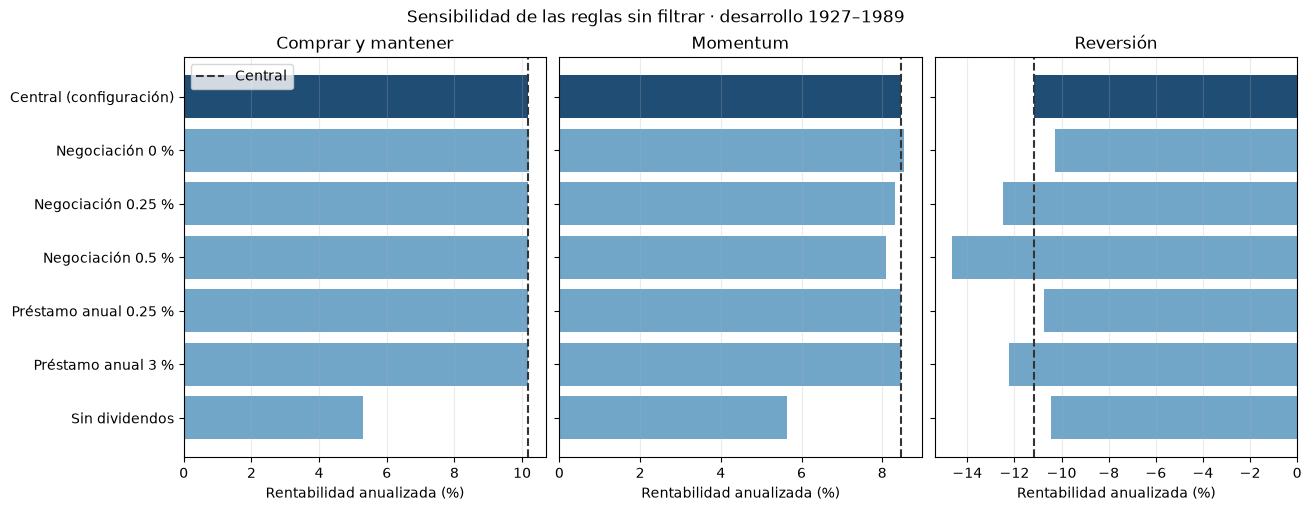

In [3]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 5), sharey=True, layout="constrained")
for eje, (estrategia, nombre) in zip(ejes, STRATEGIES.items()):
    filas = comparacion.loc[comparacion.strategy.eq(estrategia)]
    colores = ["#204d74" if caso == "central" else "#72a6c9" for caso in filas.scenario]
    eje.barh(filas.scenario_label, 100 * filas.annualized_return, color=colores)
    central = float(filas.loc[filas.scenario.eq("central"), "annualized_return"].iloc[0])
    eje.axvline(100 * central, color="#333333", linestyle="--", label="Central")
    eje.set(title=nombre, xlabel="Rentabilidad anualizada (%)")
    eje.grid(axis="x", alpha=0.25)
ejes[0].invert_yaxis()
ejes[0].legend()
fig.suptitle("Sensibilidad de las reglas sin filtrar · desarrollo 1927–1989")
plt.show()


## 4. Cómo leer los resultados

El préstamo no cambia comprar y mantener ni momentum, porque estas dos reglas no venden en corto. Sí puede cambiar reversión. Excluir dividendos elimina lo que cobra un largo y lo que debe pagar un corto, es decir, una mejora de la reversión en ese caso no demuestra que hayamos descubierto una señal mejor.

Cambiar un supuesto cada vez permite entender su efecto, pero no mide todas sus interacciones. Tampoco corrige la aproximación de Shiller ni demuestra robustez fuera de muestra. No elegiremos después la tarifa más favorable para presentar los resultados.

Esta comparación completa una comprobación de las referencias sin filtrar. Quedan las alternativas sencillas basadas en condiciones de mercado, las variables y etiquetas, los modelos y su validación temporal. La sensibilidad al retraso de señales sigue pendiente.
